# Improved Heterogeneous Graph Representation of Stiffened Panels

This walkthrough uses the **improved heterogeneous graph representation** from Paper 3, with four node types: `plate`, `force`, `edge`, and `Disp`.
The six boundary DOFs are concatenated into `Disp`. External loading remains separate.
The example is **Case 3**, the most complex three-cell box beam with double sides and hydrostatic loading. Each graph is one local stiffened panel extracted from that case. Only **32 real graphs** are bundled: 24 train, 4 validation, 4 test.

Paper 2 introduced and compared six representations. Paper 3, *A hybrid global–local computational framework for ship hull structural analysis using homogenized model and graph neural network* (Section 2.3.1), combines separate structural-edge and boundary-DOF node types with all six DOFs concatenated within each boundary node. This demo uses that improved representation and a compact residual HGT adapted from the research code. It covers the local panel surrogate, rather than the full ESL global analysis and boundary-recovery pipeline.

Run this notebook from the repository directory, after installing `requirements.txt`.
All files are local; no dataset download or user-specific path is required.

In [1]:
from pathlib import Path
import json
import torch
import numpy as np
from IPython.display import display
from dataset import ROOT, load_dataset
from demo import load_checkpoint, evaluate, plot_prediction, train
%matplotlib inline
import matplotlib.pyplot as plt

torch.set_num_threads(4)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '| PyTorch:', torch.__version__)
graphs, splits, manifest = load_dataset()
print('Split sizes:', {name: len(values) for name, values in splits.items()})

Device: cuda | PyTorch: 2.7.1+cu126


Split sizes: {'train': 24, 'val': 4, 'test': 4}


## Construct a heterogeneous graph

`dataset.py` reads the CSV rows inside `data/case3_demo.zip`. Empty padding cells are removed, features are reshaped by node type, and connection endpoints are validated. Targets are stored on plate nodes and are **not** part of `x_dict`.

The ten loading features encode the pressure samples used by this Case 3 dataset. The two legacy cached `Disp ↔ edge` endpoint arrays were reversed during export to restore valid relation directions; features and target values were preserved.

In [2]:
graph = graphs[0]
print(graph)
print('Input dimensions:', dict(graph.num_node_features))
print('Relation types:', len(graph.edge_types))
assert graph.validate(raise_on_error=True)
assert set(graph.node_types) == {'plate', 'force', 'edge', 'Disp'}
assert graph['Disp'].x.shape[1] == 6 * 60

HeteroData(
  sample_id=0,
  plate={
    x=[9, 3],
    stress=[9, 500],
    U1=[9, 500],
    U2=[9, 500],
    U3=[9, 500],
    Location=[9, 4],
  },
  force={ x=[9, 10] },
  Disp={ x=[20, 360] },
  edge={ x=[28, 10] },
  (edge, e1, plate)={ edge_index=[2, 7] },
  (edge, e2, plate)={ edge_index=[2, 7] },
  (edge, e3, plate)={ edge_index=[2, 7] },
  (edge, e4, plate)={ edge_index=[2, 7] },
  (plate, e1, edge)={ edge_index=[2, 7] },
  (plate, e2, edge)={ edge_index=[2, 7] },
  (plate, e3, edge)={ edge_index=[2, 7] },
  (plate, e4, edge)={ edge_index=[2, 7] },
  (edge, e5, plate)={ edge_index=[2, 2] },
  (edge, e6, plate)={ edge_index=[2, 2] },
  (edge, e7, plate)={ edge_index=[2, 2] },
  (edge, e8, plate)={ edge_index=[2, 2] },
  (plate, e5, edge)={ edge_index=[2, 2] },
  (plate, e6, edge)={ edge_index=[2, 2] },
  (plate, e7, edge)={ edge_index=[2, 2] },
  (plate, e8, edge)={ edge_index=[2, 2] },
  (plate, e9, force)={ edge_index=[2, 9] },
  (force, e10, plate)={ edge_index=[2, 9] },
  (D

## Load the bundled pretrained model

The model has four residual HGT layers, 64 hidden channels, and four attention heads. Standardization statistics were fitted on **4,800 Case 3 training graphs** (indices 0–4799) and are part of the checkpoint. Only 24 of those graphs are bundled. Stress outputs are restored to MPa. The checkpoint is selected using **200 separate validation graphs**, with at most 200 epochs, validation-based learning-rate reduction, and early stopping. Training on the released subset produces a different model.

The first report below is the full **999-graph** local test evaluation. The second report is recomputed from only the **four bundled test examples**. The compact network and recipe differ from the full paper experiments, even though the training sample count now matches Paper 3. The later three-epoch training cell uses only the 24 released training graphs.

In [3]:
model, checkpoint = load_checkpoint(ROOT / 'pretrained/case3_stress.pt', graph, device)
print('Parameters:', sum(p.numel() for p in model.parameters()))
print('Best epoch:', checkpoint['best_epoch'])
print('Full 999-graph test report:')
print((ROOT / 'pretrained/full_test_metrics.json').read_text())
print('Recomputed four-example report:')
metrics, true, predicted = evaluate(model, splits['test'], device)
print(json.dumps(metrics, indent=2))
zero_baseline = float(np.sqrt(np.mean(true ** 2)))
print('Zero-prediction baseline RMSE:', zero_baseline, 'MPa')

Parameters: 489732
Best epoch: 45
Full 999-graph test report:
{
  "rmse": 5.560907363891602,
  "mae": 2.80908465385437,
  "n_graphs": 999,
  "n_plate_nodes": 18631,
  "n_field_values": 9315500,
  "zero_prediction_rmse": 25.2459716796875,
  "training_samples": 4800,
  "validation_samples": 200,
  "epochs_run": 75,
  "graph_rmse_median": 3.0579428672790527,
  "graph_rmse_p90": 8.025827407836914
}
Recomputed four-example report:


{
  "rmse": 3.81828236579895,
  "mae": 1.957507610321045,
  "n_graphs": 4,
  "n_plate_nodes": 96,
  "n_field_values": 48000
}
Zero-prediction baseline RMSE: 18.10063362121582 MPa


## Reference, prediction, and error contours

Choose a test graph and plate using the zero-based indices below. Each plate has a 10 × 50 field grid. `order='F'` matches the original MATLAB column-major reshape. Coordinates are normalized local plate coordinates, not inferred global coordinates.

Original sample ID: 4800
Graph RMSE: 8.181953430175781 MPa


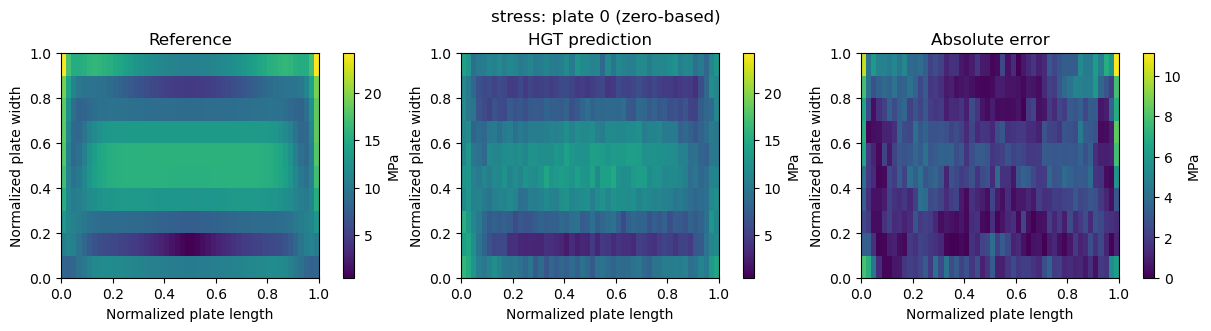

In [4]:
test_index = 0
plate_index = 0
sample = splits['test'][test_index]
sample_metrics, sample_true, sample_predicted = evaluate(model, [sample], device)
print('Original sample ID:', sample.sample_id)
print('Graph RMSE:', sample_metrics['rmse'], 'MPa')
fig = plot_prediction(sample_true, sample_predicted, plate=plate_index)
display(fig)
plt.close(fig)

## Compare field values and a representative path

The scatter uses every field value in the selected test graph. The path follows the middle row of the selected plate. The figures show the learned spatial response and remaining local errors.

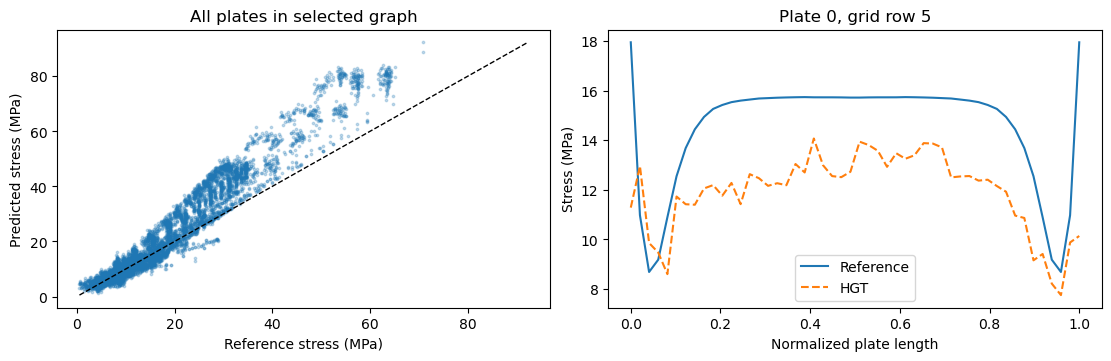

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
axes[0].scatter(sample_true.ravel(), sample_predicted.ravel(), s=3, alpha=0.25)
lim = [min(sample_true.min(), sample_predicted.min()), max(sample_true.max(), sample_predicted.max())]
axes[0].plot(lim, lim, 'k--', linewidth=1)
axes[0].set(xlabel='Reference stress (MPa)', ylabel='Predicted stress (MPa)', title='All plates in selected graph')
truth_grid = sample_true[plate_index].reshape(10, 50, order='F')
pred_grid = sample_predicted[plate_index].reshape(10, 50, order='F')
x = np.linspace(0, 1, 50)
axes[1].plot(x, truth_grid[5], label='Reference')
axes[1].plot(x, pred_grid[5], '--', label='HGT')
axes[1].set(xlabel='Normalized plate length', ylabel='Stress (MPa)', title=f'Plate {plate_index}, grid row 5')
axes[1].legend()
display(fig)
plt.close(fig)

## Effect of using more Case 3 training data

This controlled comparison uses the same Case 3 training pool, 200 validation graphs, 999 test graphs, network, optimizer, and stopping rules for 400 versus 4,800 training graphs. More graphs also means more optimization steps per epoch. Only the 4,800-graph checkpoint is distributed. The four bundled test examples are selected evenly by index, rather than by their errors.

400 training graphs: RMSE=7.2211 MPa, MAE=4.0699 MPa over 999 test graphs
4800 training graphs: RMSE=5.5609 MPa, MAE=2.8091 MPa over 999 test graphs


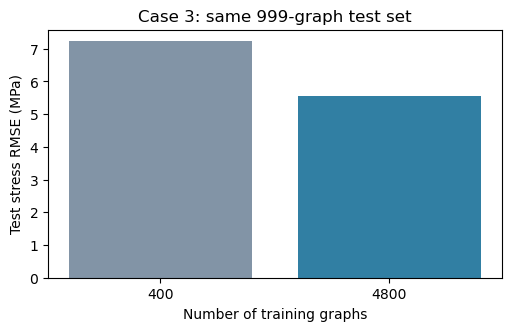

In [6]:
comparison = json.loads((ROOT / 'pretrained/data_size_comparison.json').read_text())
for size, result in comparison.items():
    print(f"{size} training graphs: RMSE={result['rmse']:.4f} MPa, MAE={result['mae']:.4f} MPa over {result['n_graphs']} test graphs")
fig, ax = plt.subplots(figsize=(5, 3.2), constrained_layout=True)
sizes = list(comparison)
ax.bar(sizes, [comparison[size]['rmse'] for size in sizes], color=['#8294a6', '#317fa3'])
ax.set(xlabel='Number of training graphs', ylabel='Test stress RMSE (MPa)', title='Case 3: same 999-graph test set')
display(fig)
plt.close(fig)

## Training history of the supplied checkpoint

Checkpoint selection uses validation MSE; the test set is used only for evaluation. The complete history is included so the pretrained example is inspectable; validation-based early stopping may finish training before 200 epochs.

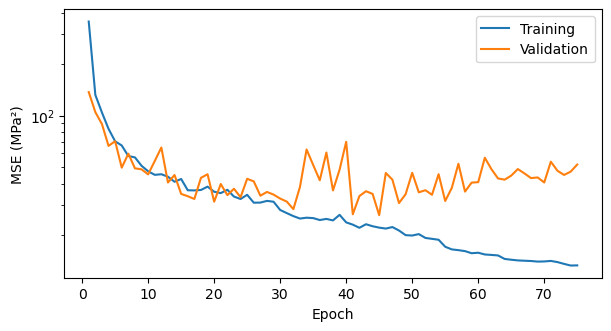

In [7]:
history = json.loads((ROOT / 'pretrained/training_history.json').read_text())
fig, ax = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
for key, label in [('train_mse', 'Training'), ('val_mse', 'Validation')]:
    ax.semilogy([h['epoch'] for h in history], [h[key] for h in history], label=label)
ax.set(xlabel='Epoch', ylabel='MSE (MPa²)')
ax.legend()
display(fig)
plt.close(fig)

## Optional: train from scratch

The following **three-epoch** run verifies optimization, validation, and checkpoint saving. It does not overwrite the bundled model, and it is too short to establish prediction accuracy. Set `RUN_TRAINING=False` to skip it. To reproduce the supplied training recipe, use 200 epochs (or the command in `README.md`). GPU timings and exact floating-point results can vary.

`target` can also be `U1`, `U2`, or `U3`; displacement targets retain their stored research scaling.

In [8]:
RUN_TRAINING = True
if RUN_TRAINING:
    fresh_model, quick_history = train(splits, ROOT / 'outputs/notebook_training', device=device,
                                       epochs=3, case=manifest['case'])
    reloaded, saved = load_checkpoint(ROOT / 'outputs/notebook_training/best_model.pt', graph, device)
    with torch.no_grad():
        fresh_model.eval()
        reloaded.eval()
        check = sample.clone().to(device)
        a = fresh_model(check.x_dict, check.edge_index_dict)['plate']
        b = reloaded(check.x_dict, check.edge_index_dict)['plate']
        torch.testing.assert_close(a, b)
    print('Saved checkpoint reproduces the trained model predictions.')

Epoch 1/3: train MSE=667.5756, val MSE=792.5328, elapsed=0.6s


Epoch 2/3: train MSE=587.6793, val MSE=702.3911, elapsed=0.8s


Epoch 3/3: train MSE=518.8508, val MSE=632.6862, elapsed=1.0s


Saved checkpoint reproduces the trained model predictions.


## Scope

This release is a compact graph-construction, training, and inference example. It omits the full database, ablation variants, and other cases. The test errors above belong to this small release and do not reproduce the paper's full benchmark results. See `data/README.md` for sample provenance, scaling, and the corrected relation orientation.